# RF Intrusion CNN v5 — Google Colab Training and Evaluation

Train and evaluate CNN v5 on a Colab GPU. The first code cell downloads the spectrogram dataset with `kagglehub`, then the notebook rebuilds the project's 40/10/10/40 split. Outputs are written under `/content/results/rf-intrusion`.

v4 remains the best overall model (test accuracy 0.8875, macro F1 0.8865). v5 targets its weak class: **Machine recall is 0.645**, and 118 of the 142 misses are predicted Benign.

## Before you run

1. In Colab, choose **Runtime → Change runtime type → A100 GPU**.
2. On the [dataset page](https://www.kaggle.com/datasets/hector484/unified-multi-class-rf-intrusion-dataset), join or accept the rules if Kaggle asks.
3. Run the cells from the top. If a Kaggle sign-in window opens, sign in and allow access.
4. Run the last cell before the session ends. It zips `results/`. Colab deletes `/content` when the runtime stops. After you download the zip, commit the small files in `results/rf-intrusion/`. Leave the `.keras` files out of git.


## 1. Download the dataset

This is the download snippet from the Kaggle dataset page.


In [2]:
%pip install -q kagglehub pandas scikit-learn matplotlib


In [3]:
import kagglehub
from pathlib import Path

# Download latest version
path = kagglehub.dataset_download("hector484/unified-multi-class-rf-intrusion-dataset")

print("Path to dataset files:", path)

root = Path(path)
candidates = [item for item in [root, root / "unified_dataset"] if (item / "train").is_dir()]
candidates += [item for item in root.rglob("unified_dataset") if (item / "train").is_dir()]
if not candidates:
    raise FileNotFoundError(f"unified_dataset/train was not inside {path}")
dataset_root = candidates[0]
Path("/content/kaggle_dataset_root.txt").write_text(str(dataset_root))
print("Dataset ready:", dataset_root)


100%|██████████| 324M/324M [00:05<00:00, 58.2MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/hector484/unified-multi-class-rf-intrusion-dataset/versions/1
Dataset ready: /root/.cache/kagglehub/datasets/hector484/unified-multi-class-rf-intrusion-dataset/versions/1/unified_dataset


In [4]:
import json
import random
import urllib.request
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)

SEED = 42
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
EXPECTED_CLASSES = ["Benign", "Broadband_Jam", "Human", "Machine", "Narrowband_Jam", "Wildlife"]
# v5 = pooling head, weight 1.0. Weight 1.25 is v5.1. A weight of 2.0 raised Machine recall to 0.965 and dropped Benign recall from 0.853 to 0.323.
MACHINE_LOSS_WEIGHT = 1.0
METADATA_URL = (
    "https://raw.githubusercontent.com/Mosizamani/aai-540-final-project-group6/"
    "main/rf_intrusion_assignment_split_metadata.csv"
)

WORKDIR = Path("/content")
DATA_ROOT = WORKDIR / "rf_assignment_split"
RESULTS_DIR = WORKDIR / "results"
ARTIFACT_DIR = RESULTS_DIR / "rf-intrusion"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

gpus = tf.config.list_physical_devices("GPU")
print("TensorFlow:", tf.__version__)
print("GPUs:", gpus)
if not gpus:
    raise RuntimeError("No GPU detected. Use Runtime → Change runtime type → A100 GPU, then rerun from the top.")
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as exc:
        print("GPU memory growth left at the Colab default:", exc)


TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Rebuild the assignment split

Kaggle's original folders are `train`, `val`, and `test`. The project mixes those images into a stratified 40/10/10/40 split: 9,600 train, 2,400 validation, 2,400 test, and 9,600 production. The class and filename assignments are the committed metadata file, so this test set is the same one used to score v4. Images are linked into `/content/rf_assignment_split` rather than copied.


In [5]:
dataset_root = Path(Path("/content/kaggle_dataset_root.txt").read_text().strip())
if not (dataset_root / "train").is_dir():
    raise FileNotFoundError("Run the kagglehub download cell above before this cell.")
print("Dataset root:", dataset_root)

source_index = {}
for original_split in ("train", "val", "test"):
    split_path = dataset_root / original_split
    assert split_path.is_dir(), split_path
    for class_dir in split_path.iterdir():
        if not class_dir.is_dir():
            continue
        for image_path in class_dir.glob("*.png"):
            source_index[(class_dir.name, image_path.name)] = image_path
print("Downloaded images:", len(source_index))

metadata_path = WORKDIR / "rf_intrusion_assignment_split_metadata.csv"
urllib.request.urlretrieve(METADATA_URL, metadata_path)
assignments = pd.read_csv(metadata_path)
assert list(assignments.columns) == [
    "image_path", "filename", "class_label", "original_split", "assignment_split"
]
assert len(assignments) == 24000

if DATA_ROOT.exists():
    import shutil
    shutil.rmtree(DATA_ROOT)

missing = 0
for row in assignments.itertuples(index=False):
    source = source_index.get((row.class_label, row.filename))
    if source is None:
        missing += 1
        continue
    target = DATA_ROOT / row.assignment_split / row.class_label / row.filename
    target.parent.mkdir(parents=True, exist_ok=True)
    target.symlink_to(source)
if missing:
    raise FileNotFoundError(f"{missing} metadata rows did not match a downloaded image.")

for split_name, expected in (("train", 9600), ("validation", 2400), ("test", 2400), ("production", 9600)):
    count = sum(1 for _ in (DATA_ROOT / split_name).glob("*/*.png"))
    print(f"{split_name}: {count}")
    assert count == expected, (split_name, count, expected)
print("Assignment split ready:", DATA_ROOT)


Dataset root: /root/.cache/kagglehub/datasets/hector484/unified-multi-class-rf-intrusion-dataset/versions/1/unified_dataset
Downloaded images: 24000
train: 9600
validation: 2400
test: 2400
production: 9600
Assignment split ready: /content/rf_assignment_split


In [6]:
train_dir = DATA_ROOT / "train"
validation_dir = DATA_ROOT / "validation"
test_dir = DATA_ROOT / "test"
class_names = sorted(path.name for path in train_dir.iterdir() if path.is_dir())
assert class_names == EXPECTED_CLASSES, class_names

def make_dataset(path, shuffle):
    return tf.keras.utils.image_dataset_from_directory(
        path,
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        label_mode="categorical",
        color_mode="rgb",
        shuffle=shuffle,
        seed=SEED if shuffle else None,
        follow_links=True,
    ).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_dir, True)
validation_ds = make_dataset(validation_dir, False)
test_ds = make_dataset(test_dir, False)
print("Classes:", class_names)


Found 9600 files belonging to 6 classes.
Found 2400 files belonging to 6 classes.
Found 2400 files belonging to 6 classes.
Classes: ['Benign', 'Broadband_Jam', 'Human', 'Machine', 'Narrowband_Jam', 'Wildlife']


## 3. v4 baseline and evaluation helper

These figures are the saved v4 test result. Machine recall is 258/400. Of the 142 misses, 118 were predicted Benign, 22 Wildlife, and 2 Human. v4 also labeled 59 true Benign images as Machine.


In [7]:
# Rows are true labels and columns are predicted labels, in EXPECTED_CLASSES order.
V4_CONFUSION = np.array([
    [341, 0, 0, 59, 0, 0],
    [1, 399, 0, 0, 0, 0],
    [0, 0, 375, 4, 0, 21],
    [118, 0, 2, 258, 0, 22],
    [0, 2, 0, 0, 398, 0],
    [0, 0, 18, 23, 0, 359],
])

def metrics_from_confusion(matrix):
    report = {}
    f1_scores = []
    for index, name in enumerate(EXPECTED_CLASSES):
        true_positive = matrix[index, index]
        support = matrix[index].sum()
        predicted = matrix[:, index].sum()
        precision = true_positive / predicted
        recall = true_positive / support
        f1 = 2 * precision * recall / (precision + recall)
        report[name] = {
            "precision": float(precision),
            "recall": float(recall),
            "f1-score": float(f1),
            "support": int(support),
        }
        f1_scores.append(f1)
    return {
        "class_names": EXPECTED_CLASSES,
        "evaluation": {
            "test_accuracy": float(np.trace(matrix) / matrix.sum()),
            "macro_f1": float(np.mean(f1_scores)),
            "classification_report": report,
            "confusion_matrix": matrix.tolist(),
        },
    }

v4_metrics = metrics_from_confusion(V4_CONFUSION)
V4_ACCURACY = v4_metrics["evaluation"]["test_accuracy"]
V4_MACRO_F1 = v4_metrics["evaluation"]["macro_f1"]
V4_MACHINE_RECALL = v4_metrics["evaluation"]["classification_report"]["Machine"]["recall"]
print(
    f"CNN v4 baseline — accuracy: {V4_ACCURACY:.4f}, macro F1: {V4_MACRO_F1:.4f}, "
    f"Machine recall: {V4_MACHINE_RECALL:.4f}"
)

def evaluate_and_save(model, version, history):
    probabilities = model.predict(test_ds, verbose=1)
    y_pred = np.argmax(probabilities, axis=1)
    y_true = np.concatenate([np.argmax(labels.numpy(), axis=1) for _, labels in test_ds])
    macro_precision, macro_recall, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    metrics = {
        "model_version": version,
        "created_utc": datetime.now(timezone.utc).isoformat(),
        "input_shape": [128, 128, 3],
        "class_names": class_names,
        "machine_loss_weight": MACHINE_LOSS_WEIGHT,
        "evaluation": {
            "test_accuracy": float(accuracy_score(y_true, y_pred)),
            "macro_precision": float(macro_precision),
            "macro_recall": float(macro_recall),
            "macro_f1": float(macro_f1),
            "classification_report": classification_report(
                y_true, y_pred, target_names=class_names, output_dict=True, zero_division=0
            ),
            "confusion_matrix": confusion_matrix(y_true, y_pred).tolist(),
        },
        "history": {key: [float(value) for value in values] for key, values in history.history.items()},
    }
    model_path = ARTIFACT_DIR / f"rf_intrusion_cnn_{version}.keras"
    metrics_path = ARTIFACT_DIR / f"rf_intrusion_cnn_{version}_metrics.json"
    model.save(model_path)
    metrics_path.write_text(json.dumps(metrics, indent=2))
    matrix = np.array(metrics["evaluation"]["confusion_matrix"])
    fig, ax = plt.subplots(figsize=(10, 8))
    ConfusionMatrixDisplay(matrix, display_labels=class_names).plot(ax=ax, cmap="Blues", values_format="d")
    ax.set_title(f"CNN {version} — Test Confusion Matrix")
    ax.tick_params(axis="x", labelrotation=45)
    fig.tight_layout()
    fig.savefig(ARTIFACT_DIR / f"rf_intrusion_cnn_{version}_confusion_matrix.png", dpi=160)
    plt.show()
    print(f"Saved {model_path} and {metrics_path.name}")
    return metrics, model_path


CNN v4 baseline — accuracy: 0.8875, macro F1: 0.8865, Machine recall: 0.6450


## 4. CNN v5

v5 keeps the v4 convolution stack and training schedule. The saved artifact is the pooling head at Machine loss weight 1.0: **v5 = pooling head, weight 1.0.** A true v5 with weight 1.25 is v5.1, already trained in section 6.

1. **Pooling head.** Global average pooling is concatenated with global max pooling, so a sparse bright machine trace is not averaged into a Benign-looking vector.
2. **Loss weight.** This saved run leaves Machine at 1.0, the same as the other five classes. A weight of 2.0 made the model call most ambiguous Benign images Machine.

Training matches v4: Adam at 0.0002, up to 30 epochs, early stopping on validation loss with patience 5 and best weights restored, and `ReduceLROnPlateau` (factor 0.5, patience 2, minimum learning rate 1e-6).


In [8]:
def conv_stage(x, filters, dropout_rate=0.0):
    """v4 stage: two 3x3 convs, then max pool and optional dropout."""
    for _ in range(2):
        x = tf.keras.layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.ReLU()(x)
    x = tf.keras.layers.MaxPooling2D()(x)
    if dropout_rate:
        x = tf.keras.layers.Dropout(dropout_rate)(x)
    return x

def weighted_categorical_crossentropy(class_weights):
    """class_weights aligns with class_names. One-hot labels select the weight."""
    weights = tf.constant(class_weights, dtype=tf.float32)

    def loss(y_true, y_pred):
        y_true = tf.cast(y_true, tf.float32)
        per_sample = tf.keras.losses.categorical_crossentropy(y_true, y_pred)
        sample_weight = tf.reduce_sum(y_true * weights, axis=-1)
        return per_sample * sample_weight

    return loss

def build_v5():
    inputs = tf.keras.Input(shape=(128, 128, 3), name="spectrogram")
    x = tf.keras.layers.Rescaling(1.0 / 255)(inputs)
    x = conv_stage(x, 32)
    x = conv_stage(x, 64, dropout_rate=0.05)
    x = conv_stage(x, 128, dropout_rate=0.08)
    x = conv_stage(x, 256, dropout_rate=0.10)
    average_pool = tf.keras.layers.GlobalAveragePooling2D()(x)
    max_pool = tf.keras.layers.GlobalMaxPooling2D()(x)
    x = tf.keras.layers.Concatenate()([average_pool, max_pool])
    x = tf.keras.layers.Dense(256, activation="relu")(x)
    x = tf.keras.layers.Dropout(0.28)(x)
    outputs = tf.keras.layers.Dense(len(class_names), activation="softmax", name="class_probabilities")(x)
    class_weights = [MACHINE_LOSS_WEIGHT if name == "Machine" else 1.0 for name in class_names]
    model = tf.keras.Model(inputs, outputs, name="rf_intrusion_cnn_v5")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=2e-4),
        loss=weighted_categorical_crossentropy(class_weights),
        metrics=["accuracy"],
    )
    return model

v5_model = build_v5()
v5_model.summary()
print("Loss weights:", {name: MACHINE_LOSS_WEIGHT if name == "Machine" else 1.0 for name in class_names})


Model: "rf_intrusion_cnn_v5"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ spectrogram         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 128, 128,  │          0 │ spectrogram[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │        864 │ rescaling[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128, 128,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │      9,216 │ re_lu[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ re_lu_1[0][0]     │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │     18,432 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │     36,864 │ re_lu_2[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 32, 32,    │          0 │ re_lu_3[0][0]     │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 32, 32,    │          0 │ max_pooling2d_1[

 Total params: 1,308,006 (4.99 MB)

 Trainable params: 1,306,086 (4.98 MB)

 Non-trainable params: 1,920 (7.50 KB)

Loss weights: {'Benign': 1.0, 'Broadband_Jam': 1.0, 'Human': 1.0, 'Machine': 1.0, 'Narrowband_Jam': 1.0, 'Wildlife': 1.0}


Epoch 1/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 52s 72ms/step - accuracy: 0.6681 - loss: 0.7832 - val_accuracy: 0.1671 - val_loss: 3.5101 - learning_rate: 2.0000e-04
Epoch 2/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 19s 64ms/step - accuracy: 0.7768 - loss: 0.4801 - val_accuracy: 0.6817 - val_loss: 0.7983 - learning_rate: 2.0000e-04
Epoch 3/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 20s 65ms/step - accuracy: 0.8116 - loss: 0.4025 - val_accuracy: 0.8062 - val_loss: 0.4117 - learning_rate: 2.0000e-04
Epoch 4/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 20s 67ms/step - accuracy: 0.8389 - loss: 0.3411 - val_accuracy: 0.8517 - val_loss: 0.3381 - learning_rate: 2.0000e-04
Epoch 5/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 20s 67ms/step - accuracy: 0.8570 - loss: 0.3053 - val_accuracy: 0.8733 - val_loss: 0.2918 - learning_rate: 2.0000e-04
Epoch 6/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 19s 62ms/step - accuracy: 0.8687 - loss: 0.2826 - val_accuracy: 0.5175 - val_loss: 2.4126 - learning_rate: 2.0000e-04
Epoch 7/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step

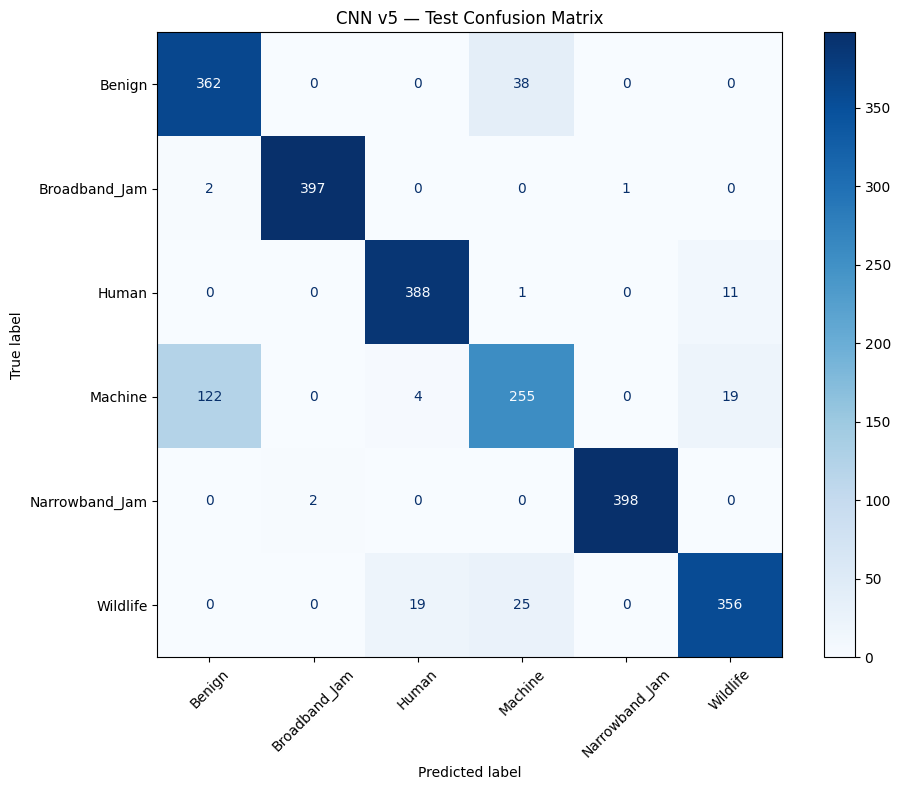

Saved /content/models/tensorflow_training/rf_intrusion_cnn_v5.keras and rf_intrusion_cnn_v5_metrics.json
CNN v5 — accuracy: 0.8983, macro F1: 0.8965, Machine recall: 0.6375


In [9]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1
    ),
]
v5_history = v5_model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=30,
    callbacks=callbacks,
    verbose=1,
)
v5_metrics, v5_path = evaluate_and_save(v5_model, "v5", v5_history)
print(
    f"CNN v5 — accuracy: {v5_metrics['evaluation']['test_accuracy']:.4f}, "
    f"macro F1: {v5_metrics['evaluation']['macro_f1']:.4f}, "
    f"Machine recall: {v5_metrics['evaluation']['classification_report']['Machine']['recall']:.4f}"
)


## 5. v4 versus v5 on Machine recall

v5 is worth keeping when Machine recall is higher than v4 and macro F1 does not fall below v4. The Benign ↔ Machine counts are the errors this version is meant to cut.


,version,accuracy,macro_f1,machine_recall,machine_precision,machine_f1,machine_as_benign,benign_as_machine,machine_correct
0,v4,0.8875,0.8865,0.6450,0.7500,0.6935,118,59,258
1,v5,0.8983,0.8965,0.6375,0.7994,0.7093,122,38,255


,v4_precision,v4_recall,v4_f1,v5_precision,v5_recall,v5_f1,recall_delta
class,,,,,,,
Benign,0.7413,0.8525,0.7930,0.7449,0.9050,0.8172,0.0525
Broadband_Jam,0.9950,0.9975,0.9963,0.9950,0.9925,0.9937,-0.0050
Human,0.9494,0.9375,0.9434,0.9440,0.9700,0.9568,0.0325
Machine,0.7500,0.6450,0.6935,0.7994,0.6375,0.7093,-0.0075
Narrowband_Jam,1.0000,0.9950,0.9975,0.9975,0.9950,0.9962,0.0000
Wildlife,0.8930,0.8975,0.8953,0.9223,0.8900,0.9059,-0.0075


HOLD: CNN v5 does not raise Machine recall. Keep v4.


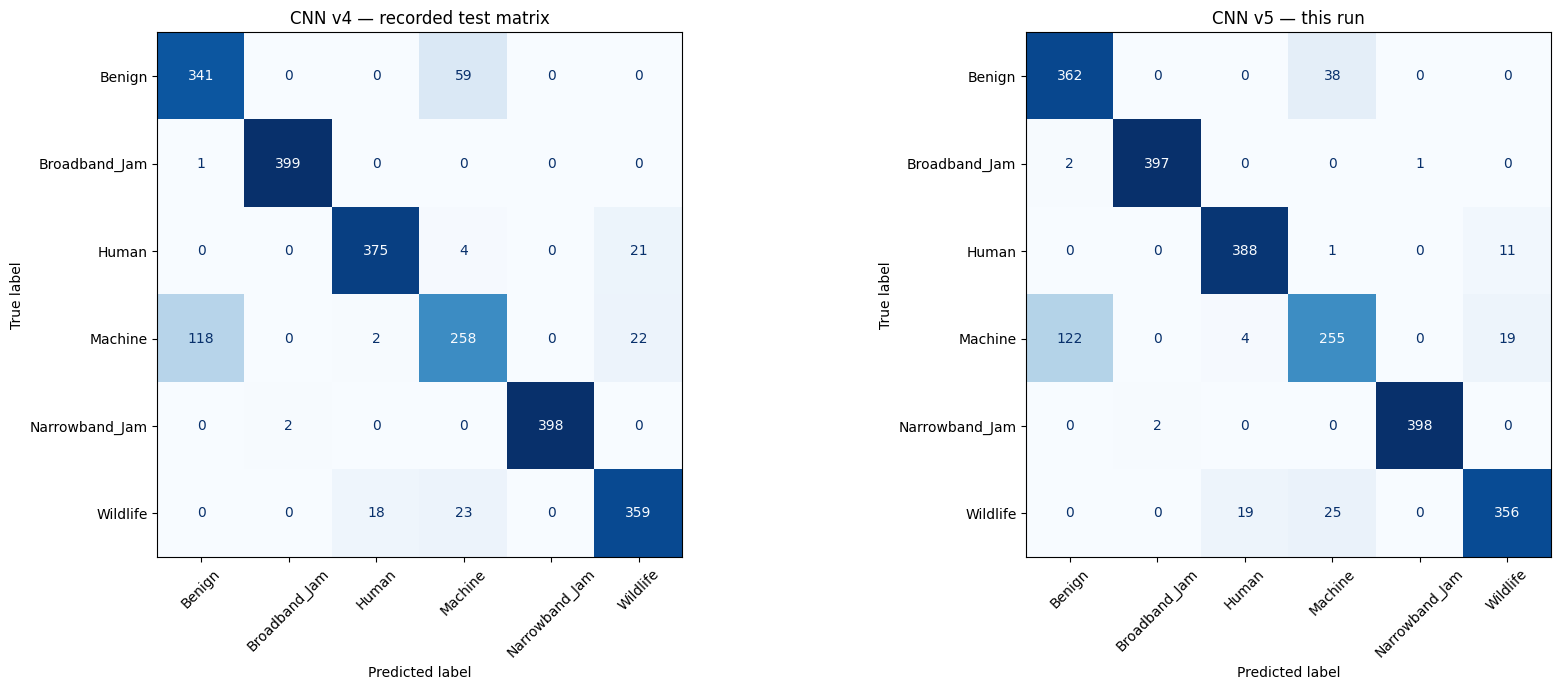

In [10]:
def swap_counts(metrics):
    labels = metrics["class_names"]
    matrix = np.array(metrics["evaluation"]["confusion_matrix"])
    benign = labels.index("Benign")
    machine = labels.index("Machine")
    return {
        "machine_as_benign": int(matrix[machine, benign]),
        "benign_as_machine": int(matrix[benign, machine]),
        "machine_correct": int(matrix[machine, machine]),
    }

v5_evaluation = v5_metrics["evaluation"]
v4_report = v4_metrics["evaluation"]["classification_report"]
v5_report = v5_evaluation["classification_report"]
v4_swaps = swap_counts(v4_metrics)
v5_swaps = swap_counts(v5_metrics)

comparison = pd.DataFrame([
    {
        "version": "v4",
        "accuracy": V4_ACCURACY,
        "macro_f1": V4_MACRO_F1,
        "machine_recall": v4_report["Machine"]["recall"],
        "machine_precision": v4_report["Machine"]["precision"],
        "machine_f1": v4_report["Machine"]["f1-score"],
        **v4_swaps,
    },
    {
        "version": "v5",
        "accuracy": v5_evaluation["test_accuracy"],
        "macro_f1": v5_evaluation["macro_f1"],
        "machine_recall": v5_report["Machine"]["recall"],
        "machine_precision": v5_report["Machine"]["precision"],
        "machine_f1": v5_report["Machine"]["f1-score"],
        **v5_swaps,
    },
])
display(comparison.style.format({
    "accuracy": "{:.4f}",
    "macro_f1": "{:.4f}",
    "machine_recall": "{:.4f}",
    "machine_precision": "{:.4f}",
    "machine_f1": "{:.4f}",
    "machine_as_benign": "{:.0f}",
    "benign_as_machine": "{:.0f}",
    "machine_correct": "{:.0f}",
}))

per_class_rows = []
for class_name in class_names:
    per_class_rows.append({
        "class": class_name,
        "v4_precision": v4_report[class_name]["precision"],
        "v4_recall": v4_report[class_name]["recall"],
        "v4_f1": v4_report[class_name]["f1-score"],
        "v5_precision": v5_report[class_name]["precision"],
        "v5_recall": v5_report[class_name]["recall"],
        "v5_f1": v5_report[class_name]["f1-score"],
        "recall_delta": v5_report[class_name]["recall"] - v4_report[class_name]["recall"],
    })
display(pd.DataFrame(per_class_rows).set_index("class").style.format("{:.4f}"))

machine_recall_up = v5_report["Machine"]["recall"] > v4_report["Machine"]["recall"]
macro_f1_held = v5_evaluation["macro_f1"] >= V4_MACRO_F1
if machine_recall_up and macro_f1_held:
    print("PASS: CNN v5 raises Machine recall and holds macro F1 at or above v4.")
elif machine_recall_up:
    print("MIXED: Machine recall is up, but macro F1 fell below v4. Keep v4 unless that trade is accepted.")
else:
    print("HOLD: CNN v5 does not raise Machine recall. Keep v4.")

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
ConfusionMatrixDisplay(V4_CONFUSION, display_labels=class_names).plot(
    ax=axes[0], cmap="Blues", values_format="d", colorbar=False
)
axes[0].set_title("CNN v4 — recorded test matrix")
axes[0].tick_params(axis="x", labelrotation=45)
ConfusionMatrixDisplay(
    np.array(v5_evaluation["confusion_matrix"]), display_labels=class_names
).plot(ax=axes[1], cmap="Blues", values_format="d", colorbar=False)
axes[1].set_title("CNN v5 — this run")
axes[1].tick_params(axis="x", labelrotation=45)
fig.tight_layout()
plt.show()


## 6. Exploratory loss-weight sweep: v5.1 through v5.6

**Exploratory, test split, not used for selection.**

Each run uses the same v5 architecture. The only change is the Machine loss weight, from 1.25 to 1.50 in steps of 0.05.

| Version | Machine loss weight |
|---|---:|
| v5.1 | 1.25 |
| v5.2 | 1.30 |
| v5.3 | 1.35 |
| v5.4 | 1.40 |
| v5.5 | 1.45 |
| v5.6 | 1.50 |

v4 is included in the results table with weight 1.00, because v4 does not upweight Machine. Run this after the data and `build_v5` cells. It trains six models. On an A100 that is about 5 to 8 minutes.

Every weight in this table was scored on the test set. Under the selection rule in section 7, weight 1.50 had the highest test Machine recall among the weights whose test macro F1 stayed at or above v4. That comparison has already been seen, so the test number from section 7 is not fully blind.



===== v5.1: Machine loss weight 1.25 =====
Epoch 1/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 31s 67ms/step - accuracy: 0.6575 - loss: 0.8443 - val_accuracy: 0.1667 - val_loss: 3.5733 - learning_rate: 2.0000e-04
Epoch 2/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 20s 66ms/step - accuracy: 0.7631 - loss: 0.5285 - val_accuracy: 0.7096 - val_loss: 0.6847 - learning_rate: 2.0000e-04
Epoch 3/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 19s 63ms/step - accuracy: 0.8045 - loss: 0.4441 - val_accuracy: 0.8379 - val_loss: 0.3948 - learning_rate: 2.0000e-04
Epoch 4/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 19s 64ms/step - accuracy: 0.8345 - loss: 0.3777 - val_accuracy: 0.8058 - val_loss: 0.4252 - learning_rate: 2.0000e-04
Epoch 5/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 20s 66ms/step - accuracy: 0.8516 - loss: 0.3372 - val_accuracy: 0.8608 - val_loss: 0.3366 - learning_rate: 2.0000e-04
Epoch 6/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 20s 64ms/step - accuracy: 0.8629 - loss: 0.3073 - val_accuracy: 0.8567 - val_loss: 0.3416 - learning_rate: 2.0000e-04
Epoch 7/

version,machine_loss_weight,accuracy,macro_f1,benign_recall,benign_precision,machine_recall,machine_precision,benign_called_machine,machine_called_benign,benign_recall_vs_v4,machine_recall_vs_v4
v4,1.0000,0.8875,0.8865,0.8525,0.7413,0.6450,0.7500,59,118,0.0000,0.0000
v5.1,1.2500,0.8746,0.8747,0.6525,0.7909,0.7500,0.6494,138,63,-0.2000,0.1050
v5.2,1.3000,0.8933,0.8929,0.8625,0.7435,0.6650,0.7557,55,115,0.0100,0.0200
v5.3,1.3500,0.8762,0.8775,0.6900,0.7731,0.7600,0.6496,123,77,-0.1625,0.1150
v5.4,1.4000,0.8842,0.8848,0.7700,0.7681,0.7275,0.6995,92,88,-0.0825,0.0825
v5.5,1.4500,0.8679,0.8672,0.5675,0.8195,0.8400,0.6292,167,47,-0.2850,0.1950
v5.6,1.5000,0.8979,0.8972,0.8625,0.7435,0.6700,0.7813,55,110,0.0100,0.0250


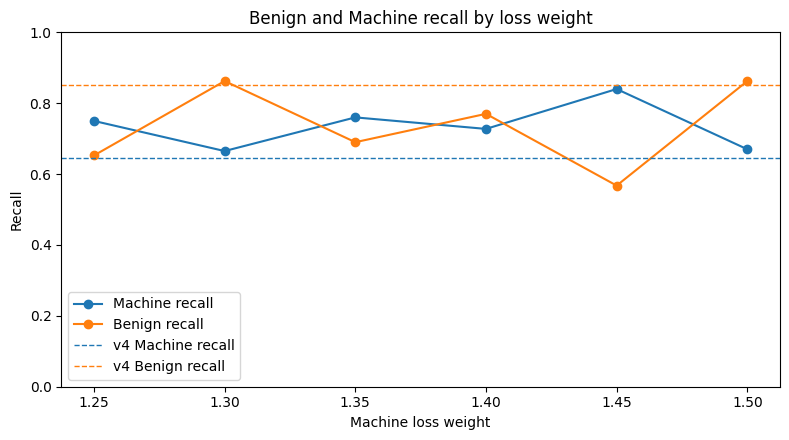

In [11]:
SWEEP = [
    ("v5.1", 1.25),
    ("v5.2", 1.30),
    ("v5.3", 1.35),
    ("v5.4", 1.40),
    ("v5.5", 1.45),
    ("v5.6", 1.50),
]

def class_counts(matrix, true_name, pred_name):
    labels = list(class_names)
    return int(matrix[labels.index(true_name), labels.index(pred_name)])

def score_split(model):
    probabilities = model.predict(test_ds, verbose=0)
    y_pred = np.argmax(probabilities, axis=1)
    y_true = np.concatenate([np.argmax(labels.numpy(), axis=1) for _, labels in test_ds])
    macro_precision, macro_recall, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    report = classification_report(
        y_true, y_pred, target_names=class_names, output_dict=True, zero_division=0
    )
    matrix = confusion_matrix(y_true, y_pred)
    return {
        "test_accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_precision": float(macro_precision),
        "macro_recall": float(macro_recall),
        "macro_f1": float(macro_f1),
        "classification_report": report,
        "confusion_matrix": matrix.tolist(),
    }

def result_row(version, weight, evaluation):
    report = evaluation["classification_report"]
    matrix = np.array(evaluation["confusion_matrix"])
    benign = report["Benign"]
    machine = report["Machine"]
    return {
        "version": version,
        "machine_loss_weight": weight,
        "accuracy": evaluation["test_accuracy"],
        "macro_f1": evaluation["macro_f1"],
        "benign_precision": benign["precision"],
        "benign_recall": benign["recall"],
        "benign_f1": benign["f1-score"],
        "machine_precision": machine["precision"],
        "machine_recall": machine["recall"],
        "machine_f1": machine["f1-score"],
        "benign_called_machine": class_counts(matrix, "Benign", "Machine"),
        "machine_called_benign": class_counts(matrix, "Machine", "Benign"),
    }

sweep_rows = [result_row("v4", 1.00, v4_metrics["evaluation"])]

for version, weight in SWEEP:
    print(f"\n===== {version}: Machine loss weight {weight:.2f} =====")
    MACHINE_LOSS_WEIGHT = weight
    tf.keras.utils.set_random_seed(SEED)
    model = build_v5()
    # New callback objects each run. Reusing them keeps the previous run's best
    # validation loss and then restores epoch-1 weights.
    sweep_callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1),
    ]
    history = model.fit(
        train_ds,
        validation_data=validation_ds,
        epochs=30,
        callbacks=sweep_callbacks,
        verbose=1,
    )
    evaluation = score_split(model)
    metrics = {
        "model_version": version,
        "created_utc": datetime.now(timezone.utc).isoformat(),
        "input_shape": [128, 128, 3],
        "class_names": class_names,
        "machine_loss_weight": weight,
        "evaluation": evaluation,
        "history": {key: [float(value) for value in values] for key, values in history.history.items()},
    }
    model_path = ARTIFACT_DIR / f"rf_intrusion_cnn_{version}.keras"
    metrics_path = ARTIFACT_DIR / f"rf_intrusion_cnn_{version}_metrics.json"
    model.save(model_path)
    metrics_path.write_text(json.dumps(metrics, indent=2))
    matrix = np.array(evaluation["confusion_matrix"])
    fig, ax = plt.subplots(figsize=(8, 6))
    ConfusionMatrixDisplay(matrix, display_labels=class_names).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(f"{version} — weight {weight:.2f}")
    ax.tick_params(axis="x", labelrotation=45)
    fig.tight_layout()
    fig.savefig(ARTIFACT_DIR / f"rf_intrusion_cnn_{version}_confusion_matrix.png", dpi=140)
    plt.close(fig)
    sweep_rows.append(result_row(version, weight, evaluation))
    print(
        f"{version}: accuracy {evaluation['test_accuracy']:.4f}, "
        f"macro F1 {evaluation['macro_f1']:.4f}, "
        f"Benign recall {evaluation['classification_report']['Benign']['recall']:.4f}, "
        f"Machine recall {evaluation['classification_report']['Machine']['recall']:.4f}"
    )
    del model

sweep_table = pd.DataFrame(sweep_rows)
v4_accuracy = float(sweep_table.loc[sweep_table["version"] == "v4", "accuracy"].iloc[0])
v4_macro_f1 = float(sweep_table.loc[sweep_table["version"] == "v4", "macro_f1"].iloc[0])
v4_benign_recall = float(sweep_table.loc[sweep_table["version"] == "v4", "benign_recall"].iloc[0])
v4_machine_recall = float(sweep_table.loc[sweep_table["version"] == "v4", "machine_recall"].iloc[0])
sweep_table["accuracy_vs_v4"] = sweep_table["accuracy"] - v4_accuracy
sweep_table["macro_f1_vs_v4"] = sweep_table["macro_f1"] - v4_macro_f1
sweep_table["benign_recall_vs_v4"] = sweep_table["benign_recall"] - v4_benign_recall
sweep_table["machine_recall_vs_v4"] = sweep_table["machine_recall"] - v4_machine_recall

sweep_csv = ARTIFACT_DIR / "v5_loss_weight_sweep.csv"
sweep_table.to_csv(sweep_csv, index=False)
print("Saved", sweep_csv)

display_columns = [
    "version", "machine_loss_weight", "accuracy", "macro_f1",
    "benign_recall", "benign_precision", "machine_recall", "machine_precision",
    "benign_called_machine", "machine_called_benign",
    "benign_recall_vs_v4", "machine_recall_vs_v4",
]
float_columns = [
    "machine_loss_weight", "accuracy", "macro_f1", "benign_recall", "benign_precision",
    "machine_recall", "machine_precision", "benign_recall_vs_v4", "machine_recall_vs_v4",
]
print("\nLoss-weight comparison against v4")
display(sweep_table[display_columns].style.format({column: "{:.4f}" for column in float_columns}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(8, 4.5))
candidates = sweep_table[sweep_table["version"] != "v4"]
ax.plot(candidates["machine_loss_weight"], candidates["machine_recall"], marker="o", label="Machine recall")
ax.plot(candidates["machine_loss_weight"], candidates["benign_recall"], marker="o", label="Benign recall")
ax.axhline(v4_machine_recall, color="C0", linestyle="--", linewidth=1, label="v4 Machine recall")
ax.axhline(v4_benign_recall, color="C1", linestyle="--", linewidth=1, label="v4 Benign recall")
ax.set_xlabel("Machine loss weight")
ax.set_ylabel("Recall")
ax.set_xticks(candidates["machine_loss_weight"])
ax.set_ylim(0, 1)
ax.legend()
ax.set_title("Benign and Machine recall by loss weight")
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / "v5_loss_weight_sweep_recall.png", dpi=140)
plt.show()


## 7. Choose the Machine weight on validation

Section 6 is exploratory, test split, not used for selection. It already scored every weight on the test set. Weight 1.50 had the highest test Machine recall among the weights whose test macro F1 stayed at or above v4, so the one test score below is not fully blind.

The rule below is fixed before these validation runs. Validation has 400 Machine images, so one training of neighboring weights (1.25 versus 1.30) is too noisy to trust. Each weight is trained three times.

**Selection rule**

1. Train Machine loss weights 1.00, 1.25, 1.30, 1.35, 1.40, 1.45, and 1.50.
2. Train each weight with seeds 42, 43, and 44. Seed 42 is the notebook seed.
3. Read only the validation split. A weight is eligible when its mean validation macro F1 across the three seeds is at least v4's recorded macro F1, 0.8865. That number is v4's test macro F1, used here only as a pre-set bar.
4. Among eligible weights, choose the highest mean validation Machine recall. If two weights tie, choose the lower weight.
5. If no weight is eligible, keep v4 and do not score a new model on the test set.
6. If a weight is chosen, score the test set once, using only the seed-42 checkpoint of that weight. No other seed or weight is scored on test.


In [12]:
SELECTION_WEIGHTS = [1.00, 1.25, 1.30, 1.35, 1.40, 1.45, 1.50]
SELECTION_SEEDS = [42, 43, 44]
TEST_SEED = SELECTION_SEEDS[0]
V4_MACRO_F1_FLOOR = V4_MACRO_F1
SELECTION_DIR = ARTIFACT_DIR / "validation_selection"
SELECTION_DIR.mkdir(parents=True, exist_ok=True)


def score_dataset(model, dataset):
    """Score one reusable tf.data split. Call this on validation until the weight is chosen."""
    probabilities = model.predict(dataset, verbose=0)
    y_pred = np.argmax(probabilities, axis=1)
    y_true = np.concatenate([np.argmax(labels.numpy(), axis=1) for _, labels in dataset])
    _, _, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    report = classification_report(
        y_true, y_pred, target_names=class_names, output_dict=True, zero_division=0
    )
    matrix = confusion_matrix(y_true, y_pred)
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1": float(macro_f1),
        "benign_recall": float(report["Benign"]["recall"]),
        "machine_recall": float(report["Machine"]["recall"]),
        "machine_precision": float(report["Machine"]["precision"]),
        "classification_report": report,
        "confusion_matrix": matrix.tolist(),
    }


def selection_checkpoint(weight, seed):
    return SELECTION_DIR / f"w{weight:.2f}_seed{seed}.weights.h5"


validation_runs = []
for weight in SELECTION_WEIGHTS:
    for seed in SELECTION_SEEDS:
        print(f"\n===== validation: weight {weight:.2f}, seed {seed} =====")
        tf.keras.utils.set_random_seed(seed)
        MACHINE_LOSS_WEIGHT = weight
        model = build_v5()
        history = model.fit(
            train_ds,
            validation_data=validation_ds,
            epochs=30,
            callbacks=[
                tf.keras.callbacks.EarlyStopping(
                    monitor="val_loss", patience=5, restore_best_weights=True, verbose=1
                ),
                tf.keras.callbacks.ReduceLROnPlateau(
                    monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1
                ),
            ],
            verbose=1,
        )
        evaluation = score_dataset(model, validation_ds)
        validation_runs.append({
            "machine_loss_weight": weight,
            "seed": seed,
            "val_accuracy": evaluation["accuracy"],
            "val_macro_f1": evaluation["macro_f1"],
            "val_benign_recall": evaluation["benign_recall"],
            "val_machine_recall": evaluation["machine_recall"],
            "val_machine_precision": evaluation["machine_precision"],
            "best_epoch": int(np.argmin(history.history["val_loss"])) + 1,
        })
        if seed == TEST_SEED:
            model.save_weights(selection_checkpoint(weight, seed))
        print(
            f"weight {weight:.2f}, seed {seed}: "
            f"val macro F1 {evaluation['macro_f1']:.4f}, "
            f"val Machine recall {evaluation['machine_recall']:.4f}"
        )
        del model

runs = pd.DataFrame(validation_runs)
summary = (
    runs.groupby("machine_loss_weight", as_index=False)
    .agg(
        mean_val_macro_f1=("val_macro_f1", "mean"),
        mean_val_machine_recall=("val_machine_recall", "mean"),
        mean_val_benign_recall=("val_benign_recall", "mean"),
        seeds=("seed", "count"),
    )
    .sort_values("machine_loss_weight")
)
summary["eligible"] = summary["mean_val_macro_f1"] >= V4_MACRO_F1_FLOOR
eligible = summary[summary["eligible"]].sort_values(
    ["mean_val_machine_recall", "machine_loss_weight"],
    ascending=[False, True],
)
chosen_weight = None if eligible.empty else float(eligible.iloc[0]["machine_loss_weight"])

print(
    f"\nEligibility floor: mean validation macro F1 >= v4 recorded macro F1 "
    f"{V4_MACRO_F1_FLOOR:.4f}"
)
display(summary.style.format({
    "machine_loss_weight": "{:.2f}",
    "mean_val_macro_f1": "{:.4f}",
    "mean_val_machine_recall": "{:.4f}",
    "mean_val_benign_recall": "{:.4f}",
}).hide(axis="index"))
runs.to_csv(SELECTION_DIR / "validation_runs.csv", index=False)
summary.to_csv(SELECTION_DIR / "validation_summary.csv", index=False)

test_evaluation = None
if chosen_weight is None:
    print("No weight met the validation macro F1 floor. Keep v4. Test set was not scored.")
else:
    print(
        f"Chosen weight {chosen_weight:.2f} by mean validation Machine recall. "
        f"Scoring test once with seed {TEST_SEED}."
    )
    MACHINE_LOSS_WEIGHT = chosen_weight
    tf.keras.utils.set_random_seed(TEST_SEED)
    chosen_model = build_v5()
    chosen_model.load_weights(selection_checkpoint(chosen_weight, TEST_SEED))
    test_evaluation = score_dataset(chosen_model, test_ds)
    chosen_path = ARTIFACT_DIR / "rf_intrusion_cnn_v5_selected.keras"
    chosen_model.save(chosen_path)
    matrix = np.array(test_evaluation["confusion_matrix"])
    fig, ax = plt.subplots(figsize=(8, 6))
    ConfusionMatrixDisplay(matrix, display_labels=class_names).plot(
        ax=ax, cmap="Blues", values_format="d", colorbar=False
    )
    ax.set_title(f"Selected v5 — weight {chosen_weight:.2f}, seed {TEST_SEED}, test once")
    ax.tick_params(axis="x", labelrotation=45)
    fig.tight_layout()
    fig.savefig(ARTIFACT_DIR / "rf_intrusion_cnn_v5_selected_confusion_matrix.png", dpi=140)
    plt.show()
    print(
        f"Test once: accuracy {test_evaluation['accuracy']:.4f}, "
        f"macro F1 {test_evaluation['macro_f1']:.4f}, "
        f"Machine recall {test_evaluation['machine_recall']:.4f}"
    )
    del chosen_model

selection_record = {
    "rule": (
        "Highest mean validation Machine recall among weights whose mean "
        "validation macro F1 is at least v4's recorded macro F1. "
        "Tie goes to the lower weight. Test is scored once, on the seed-42 "
        "checkpoint of the chosen weight only."
    ),
    "v4_macro_f1_floor": V4_MACRO_F1_FLOOR,
    "weights": SELECTION_WEIGHTS,
    "seeds": SELECTION_SEEDS,
    "test_seed": TEST_SEED,
    "validation_runs": validation_runs,
    "validation_summary": summary.to_dict(orient="records"),
    "chosen_weight": chosen_weight,
    "test_scored": test_evaluation is not None,
    "test_evaluation": test_evaluation,
}
def json_ready(value):
    if isinstance(value, np.generic):
        return value.item()
    raise TypeError(f"{type(value).__name__} is not JSON serializable")

(SELECTION_DIR / "selection_record.json").write_text(
    json.dumps(selection_record, indent=2, default=json_ready)
)
print("Saved", SELECTION_DIR / "selection_record.json")



===== validation: weight 1.00, seed 42 =====
Epoch 1/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 35s 78ms/step - accuracy: 0.6625 - loss: 0.7832 - val_accuracy: 0.1817 - val_loss: 3.5418 - learning_rate: 2.0000e-04
Epoch 2/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 19s 64ms/step - accuracy: 0.7569 - loss: 0.5071 - val_accuracy: 0.7271 - val_loss: 0.7771 - learning_rate: 2.0000e-04
Epoch 3/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 20s 66ms/step - accuracy: 0.7989 - loss: 0.4206 - val_accuracy: 0.8075 - val_loss: 0.4322 - learning_rate: 2.0000e-04
Epoch 4/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 19s 63ms/step - accuracy: 0.8363 - loss: 0.3499 - val_accuracy: 0.8708 - val_loss: 0.3098 - learning_rate: 2.0000e-04
Epoch 5/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 19s 64ms/step - accuracy: 0.8550 - loss: 0.3108 - val_accuracy: 0.8554 - val_loss: 0.3333 - learning_rate: 2.0000e-04
Epoch 6/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 19s 64ms/step - accuracy: 0.8661 - loss: 0.2906 - val_accuracy: 0.8717 - val_loss: 0.2818 - learning_rate: 2.0000e-04
Epoch 

machine_loss_weight,mean_val_macro_f1,mean_val_machine_recall,mean_val_benign_recall,seeds,eligible
1.00,0.8819,0.6167,0.8800,3,False
1.25,0.8831,0.6617,0.7892,3,False
1.30,0.8828,0.6983,0.7575,3,False
1.35,0.8792,0.7075,0.7417,3,False
1.40,0.8717,0.7367,0.6550,3,False
1.45,0.8680,0.7867,0.5800,3,False
1.50,0.8765,0.7258,0.6933,3,False


No weight met the validation macro F1 floor. Keep v4. Test set was not scored.
Saved /content/models/tensorflow_training/validation_selection/selection_record.json


## 8. Benign and Machine errors on validation

Both directions are shown. On the recorded v4 test matrix, 118 of 400 Machine images were called Benign and 59 of 400 Benign images were called Machine. The missed Machine images are the larger error. The counts below are from the validation split only. This section does not read the test set.

For a threshold `t`, the model calls Machine when `P(Machine) >= t`. Otherwise it calls the best of the other five classes. The table counts Benign→Machine and Machine→Benign at each threshold. The image grid uses the ordinary argmax prediction.

If section 7 kept v4, no v5 weight was selected. The grid and table then use the seed-42 checkpoint of the weight with the highest mean validation macro F1, as a validation diagnostic only.


No weight was selected, so v4 is kept. Validation diagnostic uses weight 1.25, seed 42, the highest mean validation macro F1. Test set is not read.


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 58 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Argmax on validation: Benign→Machine 105, Machine→Benign 95


threshold,benign_to_machine,machine_to_benign
0.1,296,0
0.2,293,0
0.3,289,0
0.4,234,29
0.5,105,96
0.6,25,144
0.7,9,158
0.8,5,165
0.9,0,179
argmax,105,95


Saved /content/models/tensorflow_training/validation_selection/validation_benign_machine_thresholds.csv


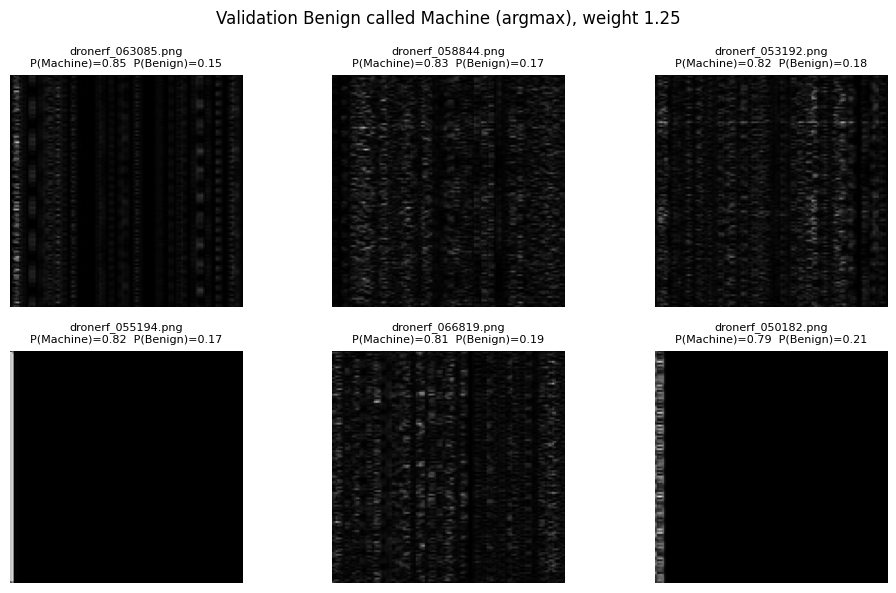

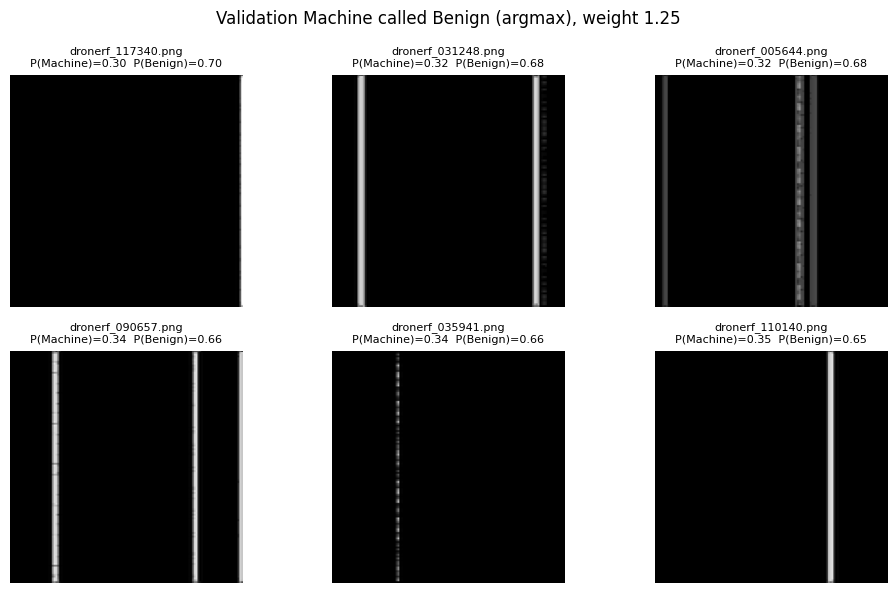

In [13]:
if chosen_weight is None:
    analysis_weight = float(
        summary.sort_values(
            ["mean_val_macro_f1", "machine_loss_weight"],
            ascending=[False, True],
        ).iloc[0]["machine_loss_weight"]
    )
    print(
        f"No weight was selected, so v4 is kept. "
        f"Validation diagnostic uses weight {analysis_weight:.2f}, seed {TEST_SEED}, "
        f"the highest mean validation macro F1. Test set is not read."
    )
else:
    analysis_weight = chosen_weight
    print(
        f"Validation errors for the selected weight {analysis_weight:.2f}, seed {TEST_SEED}. "
        f"Test set is not read."
    )

MACHINE_LOSS_WEIGHT = analysis_weight
error_model = build_v5()
error_model.load_weights(selection_checkpoint(analysis_weight, TEST_SEED))

paths = []
true_names = []
for label in ("Benign", "Machine"):
    for path in sorted((DATA_ROOT / "validation" / label).glob("*.png")):
        paths.append(path)
        true_names.append(label)
true_names = np.array(true_names)
images = np.stack([
    tf.keras.utils.img_to_array(tf.keras.utils.load_img(path, target_size=IMG_SIZE))
    for path in paths
])
probabilities = error_model.predict(images, batch_size=BATCH_SIZE, verbose=0)
machine_index = class_names.index("Machine")
benign_index = class_names.index("Benign")
other_indexes = [index for index, name in enumerate(class_names) if name != "Machine"]
argmax_index = np.argmax(probabilities, axis=1)


def predict_at_threshold(threshold):
    """Call Machine when its probability clears the threshold; otherwise call the next-best class."""
    predicted = []
    for row, machine_probability in zip(probabilities, probabilities[:, machine_index]):
        if machine_probability >= threshold:
            predicted.append(machine_index)
        else:
            predicted.append(other_indexes[int(np.argmax(row[other_indexes]))])
    return np.array(predicted)


def pair_counts(predicted_index):
    predicted_name = np.array(class_names)[predicted_index]
    benign_to_machine = int(np.sum((true_names == "Benign") & (predicted_name == "Machine")))
    machine_to_benign = int(np.sum((true_names == "Machine") & (predicted_name == "Benign")))
    return benign_to_machine, machine_to_benign


thresholds = [round(value, 1) for value in np.arange(0.1, 1.0, 0.1)]
rows = []
for threshold in thresholds:
    benign_to_machine, machine_to_benign = pair_counts(predict_at_threshold(threshold))
    rows.append({
        "threshold": f"{threshold:.1f}",
        "benign_to_machine": benign_to_machine,
        "machine_to_benign": machine_to_benign,
    })
argmax_benign_to_machine, argmax_machine_to_benign = pair_counts(argmax_index)
rows.append({
    "threshold": "argmax",
    "benign_to_machine": argmax_benign_to_machine,
    "machine_to_benign": argmax_machine_to_benign,
})
threshold_table = pd.DataFrame(rows)
print(
    f"Argmax on validation: Benign→Machine {argmax_benign_to_machine}, "
    f"Machine→Benign {argmax_machine_to_benign}"
)
display(threshold_table.style.hide(axis="index"))
threshold_path = SELECTION_DIR / "validation_benign_machine_thresholds.csv"
threshold_table.to_csv(threshold_path, index=False)
print("Saved", threshold_path)


def example_indexes(mask, rank_probabilities):
    matches = np.flatnonzero(mask)
    order = matches[np.argsort(rank_probabilities[matches])[::-1]]
    return order[:6]


def plot_examples(indexes, title):
    fig, axes = plt.subplots(2, 3, figsize=(10, 6))
    for ax, index in zip(axes.ravel(), indexes):
        ax.imshow(images[index].astype("uint8"))
        ax.set_title(
            f"{paths[index].name}\nP(Machine)={probabilities[index, machine_index]:.2f}  "
            f"P(Benign)={probabilities[index, benign_index]:.2f}",
            fontsize=8,
        )
        ax.axis("off")
    for ax in axes.ravel()[len(indexes):]:
        ax.axis("off")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

benign_as_machine = example_indexes(
    (true_names == "Benign") & (argmax_index == machine_index),
    probabilities[:, machine_index],
)
machine_as_benign = example_indexes(
    (true_names == "Machine") & (argmax_index == benign_index),
    probabilities[:, benign_index],
)
plot_examples(
    benign_as_machine,
    f"Validation Benign called Machine (argmax), weight {analysis_weight:.2f}",
)
plot_examples(
    machine_as_benign,
    f"Validation Machine called Benign (argmax), weight {analysis_weight:.2f}",
)
del error_model


## 9. Temperature scaling, then the Machine threshold

Temperature scaling does not change the predicted class. Dividing the logits by one temperature leaves the argmax unchanged, so accuracy, recall, and the confusion matrix stay the same. Its only job is to make the scores trustworthy for the agent.

The model ends in softmax, so the logits are recovered as `log(probabilities)`. That is valid here because softmax is shift-invariant: adding a constant to every logit does not change the probabilities.

Order is fixed. The temperature is fit on the validation split only, by minimizing the negative log-likelihood. The Machine threshold is chosen after that, on the calibrated validation probabilities. The test split is used once, to report expected calibration error before and after. It is not used to fit the temperature or to pick the threshold.

**Threshold rule.** On validation, call Machine when the calibrated `P(Machine)` is at least `t`; otherwise call the best of the other five classes. Consider `t` from 0.10 to 0.90 in steps of 0.05. Keep a threshold only when Benign→Machine is no higher than it is under argmax. Among those, choose the lowest Machine→Benign count. A tie goes to the higher threshold. If none qualify, keep argmax.


In [15]:
if chosen_weight is None:
    calibration_weight = float(
        summary.sort_values(
            ["mean_val_macro_f1", "machine_loss_weight"],
            ascending=[False, True],
        ).iloc[0]["machine_loss_weight"]
    )
else:
    calibration_weight = chosen_weight

MACHINE_LOSS_WEIGHT = calibration_weight
calibration_model = build_v5()
calibration_model.load_weights(selection_checkpoint(calibration_weight, TEST_SEED))
calibration_metadata = pd.read_csv(WORKDIR / "rf_intrusion_assignment_split_metadata.csv")


def load_split_probabilities(model, split_name):
    rows = calibration_metadata[calibration_metadata["assignment_split"] == split_name]
    rows = rows.sort_values("filename").reset_index(drop=True)
    paths = [
        DATA_ROOT / split_name / class_label / filename
        for filename, class_label in zip(rows["filename"].astype(str), rows["class_label"].astype(str))
    ]
    true_index = np.array([class_names.index(label) for label in rows["class_label"].astype(str)])
    batches = []
    for start in range(0, len(paths), BATCH_SIZE):
        images = np.stack([
            tf.keras.utils.img_to_array(tf.keras.utils.load_img(path, target_size=IMG_SIZE))
            for path in paths[start:start + BATCH_SIZE]
        ])
        batches.append(model.predict(images, verbose=0))
    return np.concatenate(batches, axis=0), true_index


def probabilities_at_temperature(raw_probabilities, temperature):
    """softmax(log(p) / T). The per-row shift in log(p) cancels inside softmax."""
    logits = np.log(np.clip(raw_probabilities, 1e-12, 1.0))
    scaled = logits / temperature
    scaled -= scaled.max(axis=1, keepdims=True)
    exp_scaled = np.exp(scaled)
    return exp_scaled / exp_scaled.sum(axis=1, keepdims=True)


def negative_log_likelihood(raw_probabilities, true_index, temperature):
    calibrated = probabilities_at_temperature(raw_probabilities, temperature)
    chosen = calibrated[np.arange(len(true_index)), true_index]
    return float(-np.log(np.clip(chosen, 1e-12, 1.0)).mean())


def expected_calibration_error(raw_or_calibrated, true_index, n_bins=15):
    confidence = raw_or_calibrated.max(axis=1)
    correct = (np.argmax(raw_or_calibrated, axis=1) == true_index).astype(float)
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    total = 0.0
    for start, end in zip(edges[:-1], edges[1:]):
        if end == 1.0:
            mask = (confidence >= start) & (confidence <= end)
        else:
            mask = (confidence >= start) & (confidence < end)
        if not np.any(mask):
            continue
        total += mask.mean() * abs(correct[mask].mean() - confidence[mask].mean())
    return float(total)


def decide_at_threshold(class_probabilities, threshold):
    machine_index = class_names.index("Machine")
    other = [index for index, _ in enumerate(class_names) if index != machine_index]
    chosen = np.empty(len(class_probabilities), dtype=int)
    for row_index, row in enumerate(class_probabilities):
        if row[machine_index] >= threshold:
            chosen[row_index] = machine_index
        else:
            chosen[row_index] = other[int(np.argmax(row[other]))]
    return chosen


validation_probabilities, validation_true = load_split_probabilities(calibration_model, "validation")
grid = np.exp(np.linspace(np.log(0.05), np.log(10.0), 64))
nll_grid = [negative_log_likelihood(validation_probabilities, validation_true, temperature) for temperature in grid]
left = float(grid[max(int(np.argmin(nll_grid)) - 1, 0)])
right = float(grid[min(int(np.argmin(nll_grid)) + 1, len(grid) - 1)])
for _ in range(40):
    left_third = left + (right - left) / 3
    right_third = right - (right - left) / 3
    left_nll = negative_log_likelihood(validation_probabilities, validation_true, left_third)
    right_nll = negative_log_likelihood(validation_probabilities, validation_true, right_third)
    if left_nll < right_nll:
        right = right_third
    else:
        left = left_third
FITTED_TEMPERATURE = float((left + right) / 2)

raw_nll = negative_log_likelihood(validation_probabilities, validation_true, 1.0)
fitted_nll = negative_log_likelihood(validation_probabilities, validation_true, FITTED_TEMPERATURE)
print(
    f"Temperature {FITTED_TEMPERATURE:.4f} fit on validation. "
    f"NLL {raw_nll:.4f} at T=1, {fitted_nll:.4f} after scaling."
)

calibrated_validation = probabilities_at_temperature(validation_probabilities, FITTED_TEMPERATURE)
if not np.array_equal(np.argmax(validation_probabilities, axis=1), np.argmax(calibrated_validation, axis=1)):
    raise AssertionError("Temperature scaling changed an argmax on validation.")

machine_index = class_names.index("Machine")
benign_index = class_names.index("Benign")
argmax_validation = np.argmax(calibrated_validation, axis=1)
benign_rows = validation_true == benign_index
machine_rows = validation_true == machine_index


def swap_pair(predicted):
    benign_to_machine = int(np.sum(benign_rows & (predicted == machine_index)))
    machine_to_benign = int(np.sum(machine_rows & (predicted == benign_index)))
    return benign_to_machine, machine_to_benign


base_benign_to_machine, base_machine_to_benign = swap_pair(argmax_validation)
threshold_rows = []
for threshold in np.round(np.arange(0.10, 0.95, 0.05), 2):
    benign_to_machine, machine_to_benign = swap_pair(decide_at_threshold(calibrated_validation, threshold))
    threshold_rows.append({
        "threshold": float(threshold),
        "benign_to_machine": benign_to_machine,
        "machine_to_benign": machine_to_benign,
        "eligible": benign_to_machine <= base_benign_to_machine,
    })
calibrated_threshold_table = pd.DataFrame(threshold_rows)
eligible_thresholds = calibrated_threshold_table[calibrated_threshold_table["eligible"]]
if eligible_thresholds.empty:
    MACHINE_THRESHOLD = None
    print(
        f"No threshold kept Benign→Machine at or below the argmax count "
        f"({base_benign_to_machine}). The handoff will use argmax."
    )
else:
    chosen_row = eligible_thresholds.sort_values(
        ["machine_to_benign", "threshold"], ascending=[True, False]
    ).iloc[0]
    MACHINE_THRESHOLD = float(chosen_row["threshold"])
    print(
        f"Chosen threshold {MACHINE_THRESHOLD:.2f} on calibrated validation probabilities. "
        f"Benign→Machine {int(chosen_row['benign_to_machine'])}, "
        f"Machine→Benign {int(chosen_row['machine_to_benign'])}. "
        f"Argmax was {base_benign_to_machine} and {base_machine_to_benign}."
    )
display(calibrated_threshold_table.style.format({"threshold": "{:.2f}"}).hide(axis="index"))

test_probabilities, test_true = load_split_probabilities(calibration_model, "test")
calibrated_test = probabilities_at_temperature(test_probabilities, FITTED_TEMPERATURE)
if not np.array_equal(np.argmax(test_probabilities, axis=1), np.argmax(calibrated_test, axis=1)):
    raise AssertionError("Temperature scaling changed an argmax on test.")
ECE_BEFORE = expected_calibration_error(test_probabilities, test_true)
ECE_AFTER = expected_calibration_error(calibrated_test, test_true)
print(f"Test expected calibration error: {ECE_BEFORE:.4f} before, {ECE_AFTER:.4f} after.")
print("The test split was not used to fit the temperature or to choose the threshold.")

calibration_record = {
    "temperature": FITTED_TEMPERATURE,
    "fit_split": "validation",
    "method": "temperature_scaling",
    "validation_nll_before": raw_nll,
    "validation_nll_after": fitted_nll,
    "machine_threshold": MACHINE_THRESHOLD,
    "test_ece_before": ECE_BEFORE,
    "test_ece_after": ECE_AFTER,
    "argmax_unchanged": True,
}
calibration_path = SELECTION_DIR / "calibration_record.json"
calibration_path.write_text(json.dumps(calibration_record, indent=2))
print("Saved", calibration_path)

run_config = {
    "chosen_weight": None if chosen_weight is None else float(chosen_weight),
    "threshold": None if MACHINE_THRESHOLD is None else float(MACHINE_THRESHOLD),
    "temperature": float(FITTED_TEMPERATURE),
    "seed": int(TEST_SEED),
    "selection_rule": selection_record["rule"],
    "checkpoint_weight": float(calibration_weight),
    "checkpoint_role": "selected" if chosen_weight is not None else "diagnostic",
}
run_config_path = ARTIFACT_DIR / "run_config.json"
run_config_path.write_text(json.dumps(run_config, indent=2) + "\n")
print("Saved", run_config_path)
del calibration_model


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 58 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Temperature 1.5158 fit on validation. NLL 0.2616 at T=1, 0.2453 after scaling.
Chosen threshold 0.50 on calibrated validation probabilities. Benign→Machine 102, Machine→Benign 98. Argmax was 105 and 95.


threshold,benign_to_machine,machine_to_benign,eligible
0.10,296,0,False
0.15,296,0,False
0.20,295,0,False
0.25,295,0,False
0.30,293,0,False
0.35,290,0,False
0.40,270,7,False
0.45,199,44,False
0.50,102,98,True
0.55,34,144,True


Test expected calibration error: 0.0290 before, 0.0213 after.
The test split was not used to fit the temperature or to choose the threshold.
Saved /content/models/tensorflow_training/validation_selection/calibration_record.json


## 10. Export the RF handoff CSV

The file the agent reads is the **test** split, `rf-test-outputs.csv`. Replay accepts only `split=test`. The 9,600-image production split is saved beside it as `rf-production-outputs.csv` and is not the agent handoff.

Run section 9 first. `predicted_label` uses the Machine threshold chosen there on the calibrated probabilities. `score` is the raw softmax probability of that predicted class. `calibrated_score` is the temperature-scaled probability of the same class. `calibration_method` is `temperature_scaling` and `calibration_split` is `validation`.

Before either file is written, the cell checks that the row count matches that split in the assignment metadata, that there are no NaNs, that each probability vector sums to 1, that every label is one of the six classes, and that the filenames are unique and match the metadata. The test file is then checked against the same rules as `src/validate_model_outputs.py`.

If section 7 kept v4, these scores come from the seed-42 checkpoint with the highest mean validation macro F1. `checkpoint_role` is `diagnostic` in that case, and `selected` when a weight was chosen.


In [16]:
import csv

if "FITTED_TEMPERATURE" not in globals() or "MACHINE_THRESHOLD" not in globals():
    raise RuntimeError("Run the temperature-scaling cell before exporting the handoff.")

if chosen_weight is None:
    export_weight = float(
        summary.sort_values(
            ["mean_val_macro_f1", "machine_loss_weight"],
            ascending=[False, True],
        ).iloc[0]["machine_loss_weight"]
    )
    checkpoint_role = "diagnostic"
    print(
        f"No weight was selected. Export uses the diagnostic checkpoint "
        f"weight {export_weight:.2f}, seed {TEST_SEED}."
    )
else:
    export_weight = chosen_weight
    checkpoint_role = "selected"
    print(f"Export uses the selected checkpoint weight {export_weight:.2f}, seed {TEST_SEED}.")

RF_DATASET_ID = "unified_multi_class_rf_intrusion"
RF_MODEL_VERSION = f"rf-intrusion-cnn-v5-w{export_weight:.2f}-seed{TEST_SEED}-{checkpoint_role}"
HANDOFF_COLUMNS = [
    "output_id", "sensor_type", "source_observation_id", "split", "timestamp",
    "predicted_label", "score", "model_version", "dataset_id", "source_output_ref",
    "threshold", "temperature", "calibrated_score", "calibration_method",
    "calibration_split", "checkpoint_role",
]
SPLIT_COUNTS = {"test": 2400, "production": 9600}

MACHINE_LOSS_WEIGHT = export_weight
export_model = build_v5()
export_model.load_weights(selection_checkpoint(export_weight, TEST_SEED))
metadata = pd.read_csv(WORKDIR / "rf_intrusion_assignment_split_metadata.csv")


def predict_split(split_name):
    rows = metadata[metadata["assignment_split"] == split_name].sort_values("filename").reset_index(drop=True)
    if len(rows) != SPLIT_COUNTS[split_name]:
        raise AssertionError(
            f"{split_name} metadata has {len(rows)} rows, expected {SPLIT_COUNTS[split_name]}"
        )
    filenames = rows["filename"].astype(str).to_numpy()
    paths = []
    for filename, class_label in zip(filenames, rows["class_label"].astype(str)):
        path = DATA_ROOT / split_name / class_label / filename
        if not path.is_file():
            raise FileNotFoundError(path)
        paths.append(path)
    batches = []
    for start in range(0, len(paths), BATCH_SIZE):
        images = np.stack([
            tf.keras.utils.img_to_array(tf.keras.utils.load_img(path, target_size=IMG_SIZE))
            for path in paths[start:start + BATCH_SIZE]
        ])
        batches.append(export_model.predict(images, verbose=0))
    probabilities = np.concatenate(batches, axis=0)
    if not np.isfinite(probabilities).all():
        raise AssertionError(f"{split_name} probabilities contain NaN or infinity")
    if not np.allclose(probabilities.sum(axis=1), 1.0, atol=1e-4):
        raise AssertionError(f"{split_name} probabilities do not sum to 1")
    predicted_index = np.argmax(probabilities, axis=1)
    calibrated = probabilities_at_temperature(probabilities, FITTED_TEMPERATURE)
    if not np.allclose(calibrated.sum(axis=1), 1.0, atol=1e-4):
        raise AssertionError(f"{split_name} calibrated probabilities do not sum to 1")
    if MACHINE_THRESHOLD is None:
        decision_index = predicted_index
        threshold_value = "argmax"
    else:
        decision_index = decide_at_threshold(calibrated, MACHINE_THRESHOLD)
        threshold_value = f"{MACHINE_THRESHOLD:.2f}"
    predicted_label = np.array(class_names)[decision_index]
    if not set(predicted_label).issubset(EXPECTED_CLASSES):
        raise AssertionError(f"{split_name} predicted a label outside the six classes")
    if pd.Series(filenames).duplicated().any():
        raise AssertionError(f"{split_name} filenames are not unique")
    metadata_names = set(metadata.loc[metadata["assignment_split"] == split_name, "filename"].astype(str))
    if set(filenames) != metadata_names:
        raise AssertionError(f"{split_name} filenames do not match the metadata")
    frame = pd.DataFrame({
        "output_id": [f"rf-{split_name}-{name}" for name in filenames],
        "sensor_type": "rf",
        "source_observation_id": filenames,
        "split": split_name,
        "timestamp": "source-time-unavailable",
        "predicted_label": predicted_label,
        "score": probabilities[np.arange(len(probabilities)), decision_index],
        "model_version": RF_MODEL_VERSION,
        "dataset_id": RF_DATASET_ID,
        "source_output_ref": f"rf-{split_name}-outputs.csv",
        "threshold": threshold_value,
        "temperature": f"{FITTED_TEMPERATURE:.6f}",
        "calibrated_score": calibrated[np.arange(len(calibrated)), decision_index],
        "calibration_method": "temperature_scaling",
        "calibration_split": "validation",
        "checkpoint_role": checkpoint_role,
    })
    if len(frame) != SPLIT_COUNTS[split_name]:
        raise AssertionError(f"{split_name} export has {len(frame)} rows, expected {SPLIT_COUNTS[split_name]}")
    if frame[HANDOFF_COLUMNS].isna().any().any():
        raise AssertionError(f"{split_name} export contains NaN values")
    if not frame["score"].between(0.0, 1.0).all():
        raise AssertionError(f"{split_name} scores are outside 0 to 1")
    if not frame["calibrated_score"].between(0.0, 1.0).all():
        raise AssertionError(f"{split_name} calibrated scores are outside 0 to 1")
    return frame


def assert_replay_handoff(path):
    """Same checks as src/validate_model_outputs.py. Production is not passed here."""
    with path.open(newline="", encoding="utf-8") as stream:
        reader = csv.DictReader(stream)
        columns = set(reader.fieldnames or [])
        required = {
            "output_id", "sensor_type", "source_observation_id", "split", "timestamp",
            "predicted_label", "score", "model_version", "dataset_id", "source_output_ref",
        }
        missing = required - columns
        if missing:
            raise AssertionError(f"missing required columns: {', '.join(sorted(missing))}")
        seen = set()
        count = 0
        for line, row in enumerate(reader, start=2):
            count += 1
            empty = [key for key in required if not row.get(key, "").strip()]
            if empty:
                raise AssertionError(f"line {line}: empty required values: {', '.join(sorted(empty))}")
            if row["output_id"] in seen:
                raise AssertionError(f"line {line}: duplicate output_id {row['output_id']}")
            seen.add(row["output_id"])
            if row["sensor_type"] != "rf":
                raise AssertionError(f"line {line}: sensor_type must be rf")
            if row["split"] != "test":
                raise AssertionError(f"line {line}: only held-out test outputs are allowed")
            score = float(row["score"])
            if not 0.0 <= score <= 1.0:
                raise AssertionError(f"line {line}: score must be between zero and one")
    if count != SPLIT_COUNTS["test"]:
        raise AssertionError(f"handoff has {count} rows, expected {SPLIT_COUNTS['test']}")
    return count

test_frame = predict_split("test")
production_frame = predict_split("production")
test_path = ARTIFACT_DIR / "rf-test-outputs.csv"
production_path = ARTIFACT_DIR / "rf-production-outputs.csv"
test_frame.to_csv(test_path, index=False)
production_frame.to_csv(production_path, index=False)
handoff_rows = assert_replay_handoff(test_path)
print(f"Validated {handoff_rows} test rows for the agent handoff: {test_path.name}")
print(
    f"Saved {production_path.name} ({len(production_frame)} rows). "
    "It is not the agent handoff, because replay accepts only split=test."
)
del export_model


No weight was selected. Export uses the diagnostic checkpoint weight 1.25, seed 42.


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 58 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Validated 2400 test rows for the agent handoff: rf-test-outputs.csv
Saved rf-production-outputs.csv (9600 rows). It is not the agent handoff, because replay accepts only split=test.


## 11. Download the v5 artifact

Colab removes `/content` when the runtime stops. This cell zips `results/` and downloads it. Extract `results/rf-intrusion` into the repo's `results/` folder. Commit the small files, including `run_config.json`. Leave the `.keras` files out of git; they are about 100 MB together and `*.keras` is already ignored.


In [12]:
import shutil
from google.colab import files

archive = shutil.make_archive(str(WORKDIR / "rf_intrusion_results"), "zip", WORKDIR, "results")
print("Downloading", archive)
print("Commit the small files in results/rf-intrusion. Do not commit the .keras files.")
files.download(archive)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Evaluation and data analysis

The kept model is v4. The saved v5 is the pooling head with Machine loss weight 1.0. On the 2,400-image test split its accuracy is 0.8983 and its macro F1 is 0.8965, against v4's 0.8875 and 0.8865. Its Machine recall is 0.6375, and v4's is 0.6450 (255 correct versus 258). The keep rule requires a higher Machine recall, so this run holds v4.

The error this version targets is Benign confused with Machine. On v4's recorded test matrix, 118 of 400 Machine images are called Benign and 59 of 400 Benign images are called Machine. The saved v5 cuts Benign→Machine from 59 to 38 and raises Benign recall from 0.8525 to 0.9050. Machine→Benign moves from 118 to 122. Machine precision rises from 0.7500 to 0.7994.

Section 6 retrains the same pooling head at weights 1.25 through 1.50 and scores every run on the test split. That table is exploratory. A higher Machine weight raises Machine recall at the cost of Benign recall. Weight 1.45 reaches Machine recall 0.8400 with Benign recall 0.5675 and macro F1 0.8672. Among the exploratory runs whose test macro F1 stays at or above v4's 0.8865, weight 1.50 has the highest Machine recall, 0.6700, with accuracy 0.8979 and macro F1 0.8972. Those test numbers were already seen. Section 7 is the selection.

Section 7 applies the pre-set rule on validation only, three seeds per weight. A weight is eligible when its mean validation macro F1 is at least 0.8865. That floor is v4's macro F1 from one recorded test run. Each v5 weight is the mean of three seeds, so the comparison is one v4 run against a three-seed v5 mean. The highest mean is 0.8831, at weight 1.25, and every weight finishes short of the floor. Mean validation Machine recall rises from 0.6167 at weight 1.00 to 0.7867 at weight 1.45, while mean Benign recall falls from 0.8800 to 0.5800. One seed moves the result: at weight 1.25 the three validation Machine recalls are 0.6875, 0.6975, and 0.6000. The kept model stays v4, and section 7 leaves the test split unscored.

The later tables use the seed-42 checkpoint of weight 1.25, the highest mean validation macro F1. They are diagnostic. On its validation predictions, argmax gives 105 Benign→Machine and 95 Machine→Benign. A cutoff away from about 0.5 trades one error for the other: at 0.3, Machine→Benign is 0 and 289 Benign images are called Machine; at 0.7, Benign→Machine is 9 and Machine→Benign is 158.

Temperature 1.5158 is fit on that same validation split. Validation negative log-likelihood falls from 0.2616 to 0.2453, and the argmax stays the same. On the test split, expected calibration error in 15 equal-width bins falls from 0.0290 to 0.0213. The test split is used only for that report. The Machine threshold is then chosen on the calibrated validation probabilities. The chosen threshold is 0.50: Benign→Machine is 102, within the argmax count of 105, and Machine→Benign is 98. At the next eligible threshold, 0.55, Benign→Machine is 34 and Machine→Benign is 144.

The agent file is `rf-test-outputs.csv`, 2,400 test rows, from this diagnostic checkpoint, with temperature 1.5158 and threshold 0.50. `rf-production-outputs.csv` has the 9,600 production rows. Replay reads only the test file. The handoff records a diagnostic v5 checkpoint. This evaluation keeps the v4 model.
